In [1]:
from pathlib import Path

DATASET_DIR = Path("Wildfire Smoke.v1-raw.yolov8")

print("Dataset exists:", DATASET_DIR.exists())
print("Contents:", [item.name for item in DATASET_DIR.iterdir()])

Dataset exists: True
Contents: ['data.yaml', 'README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [2]:
%pip install ultralytics

In [3]:
import sys
print(sys.executable)

C:\Users\aizat\anaconda3\python.exe


In [4]:
import numpy as np
import cv2
import torch
import ultralytics

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

NumPy: 1.26.4
OpenCV: 4.10.0
Ultralytics: 8.4.215
GPU available: False


In [5]:
from pathlib import Path

DATASET_DIR = Path("Wildfire Smoke.v1-raw.yolov8")

print("Dataset folder:", DATASET_DIR.resolve())
print("\ndata.yaml:")
print((DATASET_DIR / "data.yaml").read_text(encoding="utf-8"))

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "valid", "test"]:
    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"

    images = [p for p in image_dir.rglob("*") if p.suffix.lower() in image_extensions]
    labels = list(label_dir.rglob("*.txt"))

    print(f"\n{split}: {len(images)} images, {len(labels)} label files")

    if labels:
        print("Example label:")
        print(labels[0].read_text(encoding="utf-8").strip())

Dataset folder: C:\Users\aizat\Downloads\DEEP LEARNING 2026\Wildfire Smoke.v1-raw.yolov8

data.yaml:
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['smoke']

roboflow:
  workspace: brad-dwyer
  project: wildfire-smoke
  version: 1
  license: BY-NC-SA 4.0
  url: https://universe.roboflow.com/brad-dwyer/wildfire-smoke/dataset/1

train: 516 images, 516 label files
Example label:
0 0.76953125 0.453125 0.1421875 0.09375

valid: 147 images, 147 label files
Example label:
0 0.69453125 0.47291666666666665 0.1515625 0.06666666666666667

test: 74 images, 74 label files
Example label:
0 0.63203125 0.6072916666666667 0.3671875 0.10625


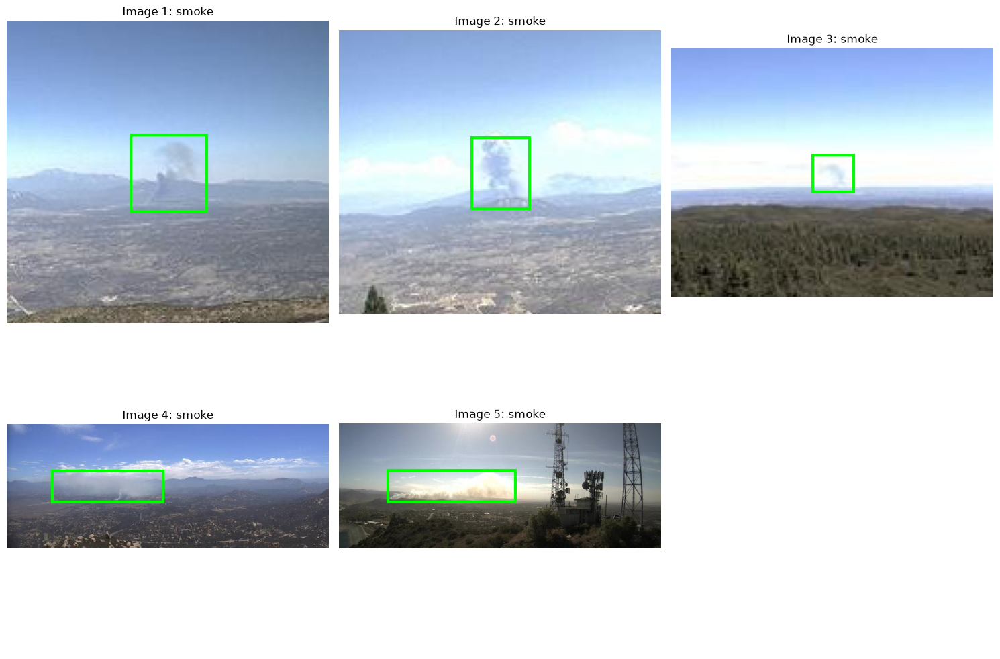

In [6]:
from pathlib import Path
import random
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image


DATASET_DIR = Path("Wildfire Smoke.v1-raw.yolov8")
image_dir = DATASET_DIR / "train" / "images"
label_dir = DATASET_DIR / "train" / "labels"


image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
images = sorted(
    path for path in image_dir.iterdir()
    if path.suffix.lower() in image_extensions
)

random.seed(42)
chosen_images = random.sample(images, min(5, len(images)))

crops = []

for number, image_path in enumerate(chosen_images, start=1):

    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    label_path = label_dir / f"{image_path.stem}.txt"

    if not label_path.exists():
        continue


    for row in label_path.read_text(encoding="utf-8").splitlines():
        values = row.split()
        class_id = int(values[0])
        x_center, y_center, box_width, box_height = map(float, values[1:5])

        # Converting the box coordinates from 0-to-1 values to pixels
        x1 = int((x_center - box_width / 2) * width)
        y1 = int((y_center - box_height / 2) * height)
        x2 = int((x_center + box_width / 2) * width)
        y2 = int((y_center + box_height / 2) * height)

        # Adding extra space around the box so nearby smoke is visible
        pad_x = max(int(width * 0.12), int((x2 - x1) * 1.5))
        pad_y = max(int(height * 0.12), int((y2 - y1) * 1.5))

        # Keeping the crop inside the image
        left = max(0, x1 - pad_x)
        top = max(0, y1 - pad_y)
        right = min(width, x2 + pad_x)
        bottom = min(height, y2 + pad_y)

        crop = image.crop((left, top, right, bottom))

        # Drawing the original labeled box on the zoomed crop
        draw = patches.Rectangle(
            (x1 - left, y1 - top),
            x2 - x1,
            y2 - y1,
            linewidth=3,
            edgecolor="lime",
            facecolor="none"
        )

        crops.append((crop, draw, f"Image {number}: smoke"))

# Displaying the zoomed crops
columns = 3
rows = math.ceil(len(crops) / columns)
fig, axes = plt.subplots(rows, columns, figsize=(15, 5 * rows))
axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

for ax, (crop, box, title) in zip(axes, crops):
    ax.imshow(crop)
    ax.add_patch(box)
    ax.set_title(title)
    ax.axis("off")

# Hiding any unused plot spaces
for ax in axes[len(crops):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
from ultralytics import YOLO

MODEL_NAME = "yolov8n.pt"

model = YOLO(MODEL_NAME)

pretrained_classes = list(model.names.values())

print("Checkpoint:", MODEL_NAME)
print("Number of pretrained classes:", len(pretrained_classes))
print("Does it already include smoke?",
      any(name.lower() == "smoke" for name in pretrained_classes))
print("Some pretrained classes:", pretrained_classes[:10])

Checkpoint: yolov8n.pt
Number of pretrained classes: 80
Does it already include smoke? False
Some pretrained classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light']


In [8]:
from pathlib import Path
from ultralytics import YOLO

DATASET_DIR = Path("Wildfire Smoke.v1-raw.yolov8")
DATA_YAML = DATASET_DIR / "data.yaml"


model = YOLO("yolov8n.pt")


results = model.train(
    data=str(DATA_YAML),       
    epochs=30,                  
    imgsz=640,                  
    batch=8,                    
    device="cpu",               
    workers=0,                  
    seed=42,                    
    project="runs/detect",     
    name="wildfire_baseline"    
)

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.215  Python-3.12.7 torch-2.14.1+cpu CPU (AMD Ryzen 5 5500U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Wildfire Smoke.v1-raw.yolov8\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, mo

Run folder: C:\Users\aizat\Downloads\DEEP LEARNING 2026\runs\detect\runs\detect\wildfire_baseline-2
Best validation epoch: 26.0

Best epoch's validation metrics:
metrics/precision(B): 0.8571
metrics/recall(B): 0.8980
metrics/mAP50(B): 0.9522
metrics/mAP50-95(B): 0.5067

Best checkpoint exists: True
Last checkpoint exists: True


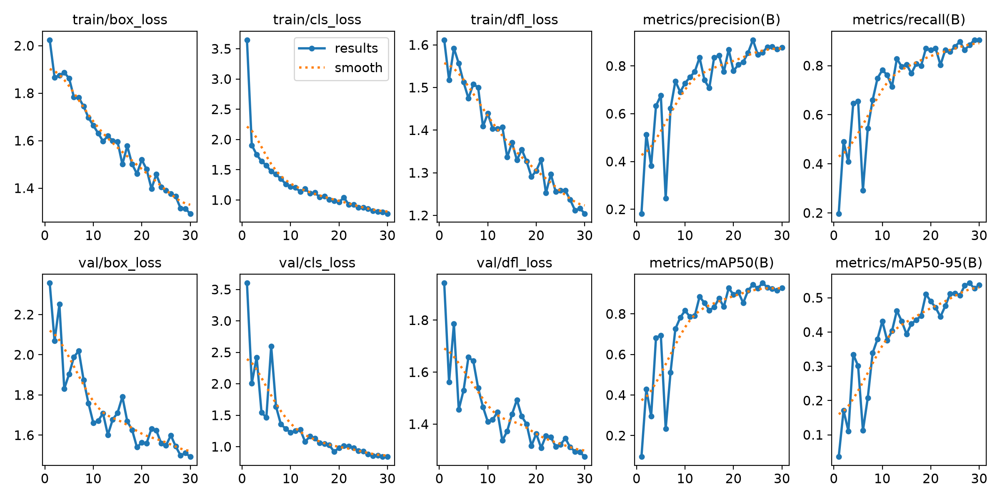

In [9]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display


RUN_DIR = Path("runs/detect/runs/detect/wildfire_baseline-2")
results_file = RUN_DIR / "results.csv"


results_df = pd.read_csv(results_file)
results_df.columns = results_df.columns.str.strip()


map50_column = next(
    column for column in results_df.columns
    if "mAP50" in column and "95" not in column
)
best_row = results_df.loc[results_df[map50_column].idxmax()]

print("Run folder:", RUN_DIR.resolve())
print("Best validation epoch:", best_row["epoch"])
print("\nBest epoch's validation metrics:")

for column in results_df.columns:
    if column.startswith("metrics/"):
        print(f"{column}: {best_row[column]:.4f}")


print("\nBest checkpoint exists:",
      (RUN_DIR / "weights" / "best.pt").exists())
print("Last checkpoint exists:",
      (RUN_DIR / "weights" / "last.pt").exists())


curves_file = RUN_DIR / "results.png"
if curves_file.exists():
    display(Image(filename=str(curves_file)))

Hypothesis: Reducing the image size from 640 to 512 will reduce training time, but may lower smoke detection performance because faint smoke regions can be small.

In [10]:
from pathlib import Path
from ultralytics import YOLO


DATASET_DIR = Path("Wildfire Smoke.v1-raw.yolov8")
DATA_YAML = (DATASET_DIR / "data.yaml").resolve()


RUNS_DIR = str((Path.cwd() / "runs" / "detect").resolve())


experiment_model = YOLO("yolov8n.pt")


experiment_results = experiment_model.train(
    data=str(DATA_YAML),
    epochs=30,
    imgsz=512,                 # Changed from 640
    batch=8,
    device="cpu",
    workers=0,
    seed=42,
    project=RUNS_DIR,
    name="wildfire_imgsz512"
)

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.215  Python-3.12.7 torch-2.14.1+cpu CPU (AMD Ryzen 5 5500U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\aizat\Downloads\DEEP LEARNING 2026\Wildfire Smoke.v1-raw.yolov8\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rat

In [11]:
from pathlib import Path
from ultralytics import YOLO


DATA_YAML = Path("Wildfire Smoke.v1-raw.yolov8/data.yaml").resolve()
BASELINE_BEST = Path(
    "runs/detect/runs/detect/wildfire_baseline-2/weights/best.pt"
)
EXPERIMENT_BEST = Path(
    "runs/detect/wildfire_imgsz512/weights/best.pt"
)


runs = [
    ("640 baseline", BASELINE_BEST, 640),
    ("512 experiment", EXPERIMENT_BEST, 512),
]

for run_name, checkpoint, image_size in runs:
    print(f"\nEvaluating {run_name}: {checkpoint}")

    model = YOLO(str(checkpoint))
    metrics = model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=image_size,
        batch=8,
        device="cpu",
        workers=0,
        conf=0.001,
        iou=0.7,
        plots=False
    )

    print(f"Precision:   {metrics.box.mp:.4f}")
    print(f"Recall:      {metrics.box.mr:.4f}")
    print(f"mAP@0.50:    {metrics.box.map50:.4f}")
    print(f"mAP@0.50:0.95: {metrics.box.map:.4f}")


Evaluating 640 baseline: runs\detect\runs\detect\wildfire_baseline-2\weights\best.pt
Ultralytics 8.4.215  Python-3.12.7 torch-2.14.1+cpu CPU (AMD Ryzen 5 5500U with Radeon Graphics)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 60.1±11.2 MB/s, size: 39.1 KB)
val: Scanning C:\Users\aizat\Downloads\DEEP LEARNING 2026\Wildfire Smoke.v1-raw.yolov8\valid\labels.cache... 147 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 147/147  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.0it/s 9.6s0.5s
                   all        147        147      0.879      0.884      0.924      0.543
Speed: 1.8ms preprocess, 53.1ms inference, 0.0ms loss, 0.9ms postprocess per image
Precision:   0.8786
Recall:      0.8844
mAP@0.50:    0.9240
mAP@0.50:0.95: 0.5429

Evaluating 512 experiment: runs\detect\wildfire_imgsz512\weights\best.pt
Ultralytics 8.4.215

In [12]:
from pathlib import Path
from ultralytics import YOLO


DATA_YAML = Path("Wildfire Smoke.v1-raw.yolov8/data.yaml").resolve()
FINAL_CHECKPOINT = Path(
    "runs/detect/runs/detect/wildfire_baseline-2/weights/best.pt"
)

final_model = YOLO(str(FINAL_CHECKPOINT))


test_metrics = final_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device="cpu",
    workers=0,
    conf=0.001,
    iou=0.7
)

print(f"Test precision: {test_metrics.box.mp:.4f}")
print(f"Test recall: {test_metrics.box.mr:.4f}")
print(f"Test mAP@0.50: {test_metrics.box.map50:.4f}")
print(f"Test mAP@0.50:0.95: {test_metrics.box.map:.4f}")

Ultralytics 8.4.215  Python-3.12.7 torch-2.14.1+cpu CPU (AMD Ryzen 5 5500U with Radeon Graphics)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.2±0.1 ms, read: 2.9±0.9 MB/s, size: 35.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\aizat\Downloads\DEEP LEARNING 2026\Wildfire Smoke.v1-raw.yolov8\test\labels... 74 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 74/74 275.5it/s 0.3s0.1s
val: New cache created: C:\Users\aizat\Downloads\DEEP LEARNING 2026\Wildfire Smoke.v1-raw.yolov8\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.6it/s 6.3s.7ss
                   all         74         74      0.861      0.946      0.947      0.554
Speed: 2.4ms preprocess, 68.7ms inference, 0.0ms loss, 1.0ms postprocess pe

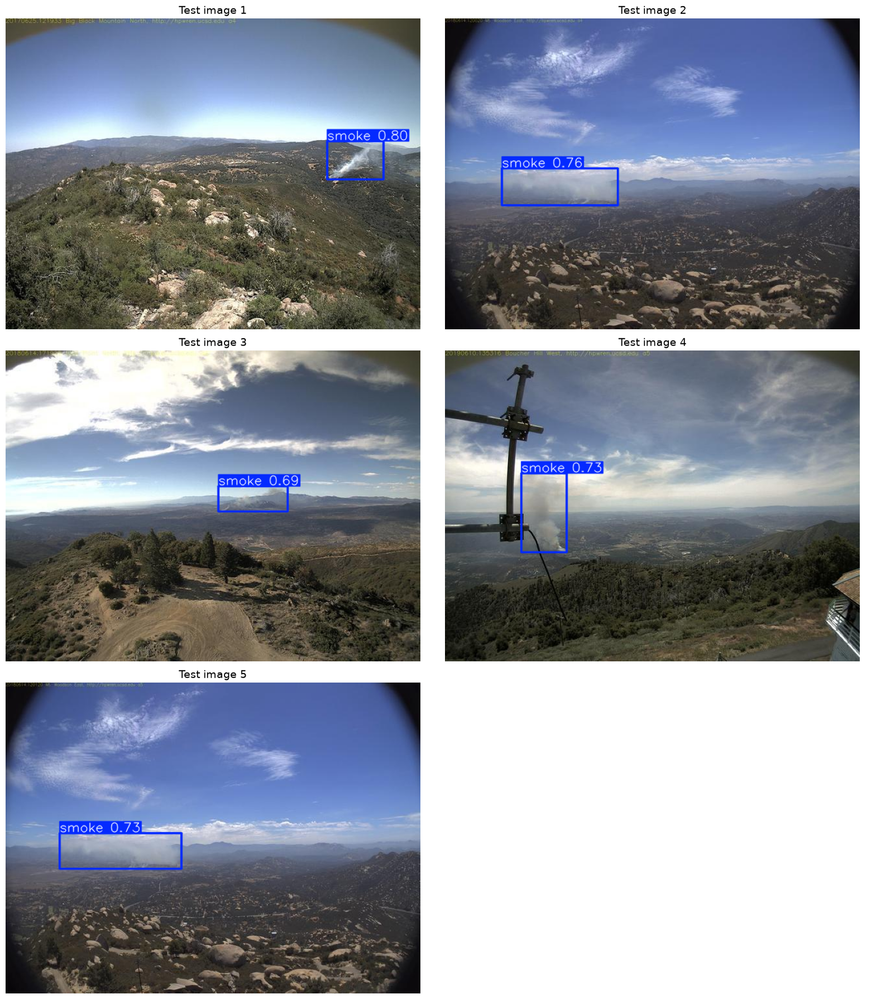

In [14]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO

# Load the selected 640-pixel model
FINAL_CHECKPOINT = Path(
    "runs/detect/runs/detect/wildfire_baseline-2/weights/best.pt"
)
final_model = YOLO(str(FINAL_CHECKPOINT))

# Find the test images
TEST_IMG_DIR = Path("Wildfire Smoke.v1-raw.yolov8/test/images")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
test_images = sorted(
    path for path in TEST_IMG_DIR.iterdir()
    if path.suffix.lower() in image_extensions
)

# Choose five test images in a repeatable random order
random.seed(42)
chosen_test_images = random.sample(test_images, min(5, len(test_images)))

# Predict smoke boxes for those images
predictions = final_model.predict(
    source=[str(path) for path in chosen_test_images],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device="cpu",
    verbose=False
)

# Make a larger grid: two images per row
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for number, (ax, prediction) in enumerate(zip(axes, predictions), start=1):
    # Draw the predicted boxes, class names, and confidence scores
    annotated_image = prediction.plot(labels=True, conf=True)
    annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

    ax.imshow(annotated_image)
    ax.set_title(f"Test image {number}", fontsize=14)
    ax.axis("off")

# Hide the unused sixth space
for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
from pathlib import Path
import numpy as np

# Find all test images and their labels
TEST_IMG_DIR = Path("Wildfire Smoke.v1-raw.yolov8/test/images")
TEST_LABEL_DIR = Path("Wildfire Smoke.v1-raw.yolov8/test/labels")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
test_images = sorted(
    path for path in TEST_IMG_DIR.iterdir()
    if path.suffix.lower() in image_extensions
)

# Predict on all test images at the same display confidence threshold
all_predictions = final_model.predict(
    source=[str(path) for path in test_images],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device="cpu",
    verbose=False
)

def calculate_iou(box_a, box_b):
    # Find the shared area of two boxes
    left = max(box_a[0], box_b[0])
    top = max(box_a[1], box_b[1])
    right = min(box_a[2], box_b[2])
    bottom = min(box_a[3], box_b[3])

    intersection = max(0, right - left) * max(0, bottom - top)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0

possible_errors = []

for image_path, prediction in zip(test_images, all_predictions):
    # Read the image size and its ground-truth boxes
    image_height, image_width = prediction.orig_shape
    label_path = TEST_LABEL_DIR / f"{image_path.stem}.txt"
    ground_truth_boxes = []

    for line in label_path.read_text(encoding="utf-8").splitlines():
        values = line.split()
        _, x_center, y_center, box_width, box_height = map(float, values[:5])

        # Convert normalized YOLO coordinates to pixel coordinates
        ground_truth_boxes.append([
            (x_center - box_width / 2) * image_width,
            (y_center - box_height / 2) * image_height,
            (x_center + box_width / 2) * image_width,
            (y_center + box_height / 2) * image_height
        ])

    # Get YOLO's predicted boxes
    if prediction.boxes is None:
        predicted_boxes = []
    else:
        predicted_boxes = prediction.boxes.xyxy.cpu().numpy().tolist()

    # Compare each ground-truth box with the predictions
    missed = 0
    for ground_truth_box in ground_truth_boxes:
        best_overlap = max(
            [calculate_iou(ground_truth_box, box) for box in predicted_boxes],
            default=0
        )
        if best_overlap < 0.50:
            missed += 1

    # Flag predictions that don't match any ground-truth box
    extra = 0
    for predicted_box in predicted_boxes:
        best_overlap = max(
            [calculate_iou(predicted_box, box) for box in ground_truth_boxes],
            default=0
        )
        if best_overlap < 0.50:
            extra += 1

    if missed or extra:
        possible_errors.append((image_path.name, missed, extra))

# Print images for us to inspect
print("Possible error cases:")
for filename, missed, extra in possible_errors:
    print(f"{filename}: missed smoke boxes={missed}, extra boxes={extra}")

if not possible_errors:
    print("No possible errors found at confidence 0.25 and IoU 0.50.")

Possible error cases:
ck0kn966blrt008482afk6mhy_jpeg.rf.87c1a2bec2d604d4201f5a4f1c202b7c.jpg: missed smoke boxes=1, extra boxes=2
ck0lxa18hic880701ux5axl97_jpeg.rf.abdfc2e5ff468070ce99f220db3a15ac.jpg: missed smoke boxes=0, extra boxes=1
ck0rp8yjl4f5b0838yi4z8ub1_jpeg.rf.c52a2a36149132c02b54dd563a7e8ae8.jpg: missed smoke boxes=0, extra boxes=2
ck0rqf6p055aw0838g7rq1u9v_jpeg.rf.6d20312e29819ab26cdf6da38f885548.jpg: missed smoke boxes=0, extra boxes=1
ck0rqkhjb4o7k0863lhsglv38_jpeg.rf.bead4c393b360becf1513484f1814b97.jpg: missed smoke boxes=1, extra boxes=1
ck0twbr4hwf330721j3vv8j30_jpeg.rf.9d5b13b7676972682caea0e57b46b462.jpg: missed smoke boxes=0, extra boxes=1
ck0twvs9zu5t00944ltnvijnz_jpeg.rf.f16fd720d3e940c5c4243fcfe42152cc.jpg: missed smoke boxes=1, extra boxes=1
ck0tzttgusl7o0863k0kfvcid_jpeg.rf.e7e63b78205057a6cca97e1a9f243c27.jpg: missed smoke boxes=0, extra boxes=1
ck0tzzys2sm6b0863k8qyy7hp_jpeg.rf.bed377d6bb1fe0d5ac11d08324055def.jpg: missed smoke boxes=1, extra boxes=1
ck0u0e

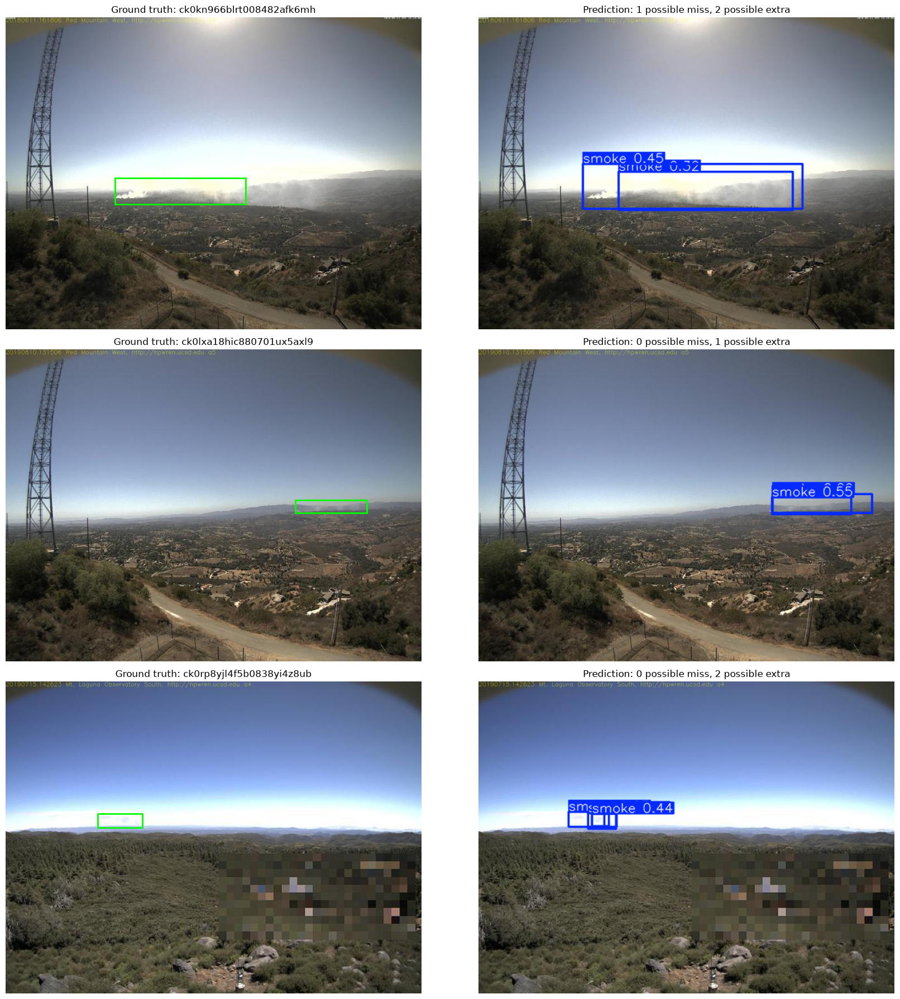

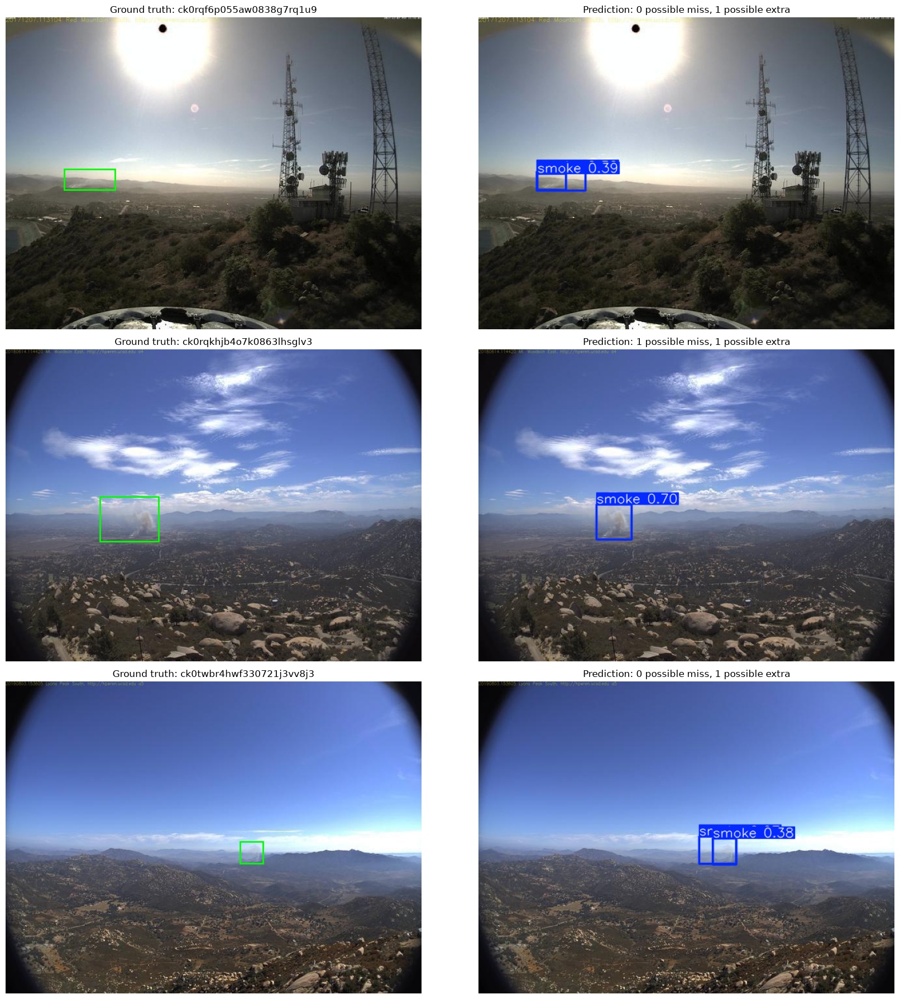

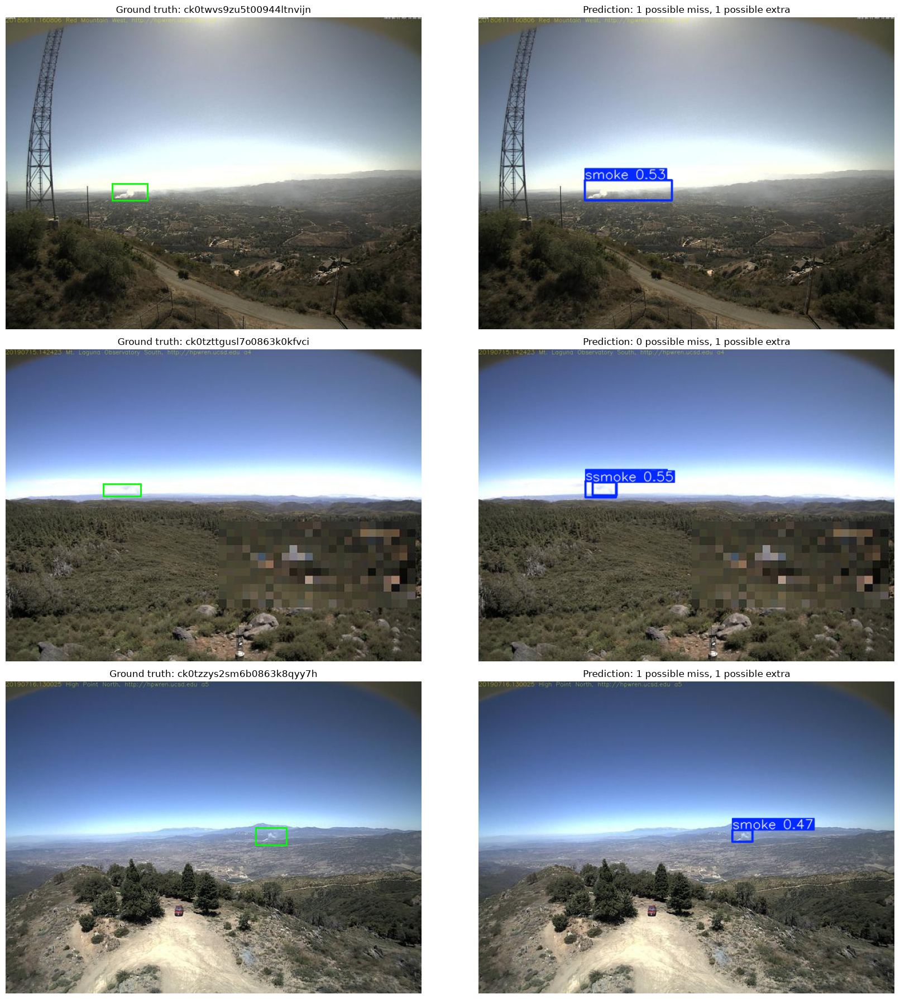

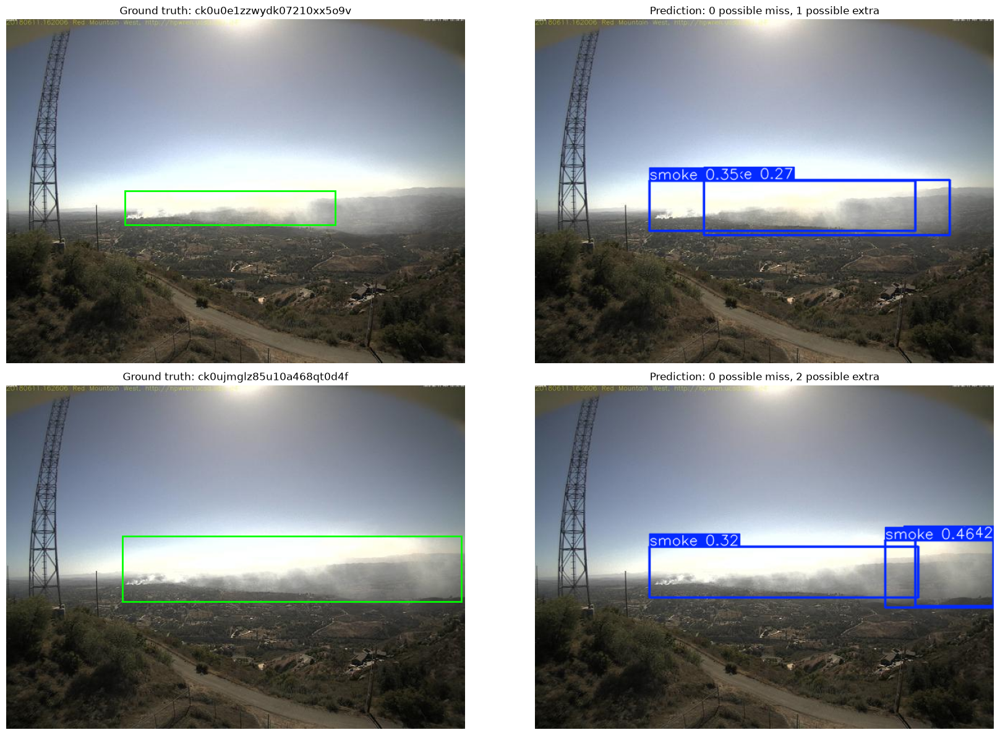

In [18]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import cv2


prediction_by_name = {
    Path(result.path).name: result
    for result in all_predictions
}

for start in range(0, len(possible_errors), 3):
    cases = possible_errors[start:start + 3]

    fig, axes = plt.subplots(
        len(cases), 2,
        figsize=(18, 6 * len(cases))
    )


    if len(cases) == 1:
        axes = [axes]

    for row_axes, (filename, missed, extra) in zip(axes, cases):
        ground_truth_ax, prediction_ax = row_axes
        image_path = TEST_IMG_DIR / filename


        image = Image.open(image_path).convert("RGB")
        width, height = image.size
        ground_truth_ax.imshow(image)

        label_path = TEST_LABEL_DIR / f"{image_path.stem}.txt"

        for line in label_path.read_text(encoding="utf-8").splitlines():
            values = line.split()
            _, x_center, y_center, box_width, box_height = map(
                float, values[:5]
            )

            x = (x_center - box_width / 2) * width
            y = (y_center - box_height / 2) * height

            rectangle = patches.Rectangle(
                (x, y),
                box_width * width,
                box_height * height,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )
            ground_truth_ax.add_patch(rectangle)

        ground_truth_ax.set_title(f"Ground truth: {filename[:24]}")
        ground_truth_ax.axis("off")


        prediction = prediction_by_name[filename]
        annotated = prediction.plot(labels=True, conf=True)
        annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

        prediction_ax.imshow(annotated)
        prediction_ax.set_title(
            f"Prediction: {missed} possible miss, {extra} possible extra"
        )
        prediction_ax.axis("off")

    plt.tight_layout()
    plt.show()